In [32]:

X_config = ["hum_carrasco","hum_salto","tmax_carrasco","tmin_carrasco","tmax_salto","tmin_salto",
    "dir_viento_carrasco_prom","int_viento_carrasco_prom",
    "int_racha_viento_carrasco_prom","dir_viento_salto_prom","int_viento_salto_prom",
    "int_racha_viento_salto_prom","vis_carrasco_prom","vis_salto_prom","fen_carrasco_17", "fase_lunar"]

y_config = ["dia_lluvioso"]

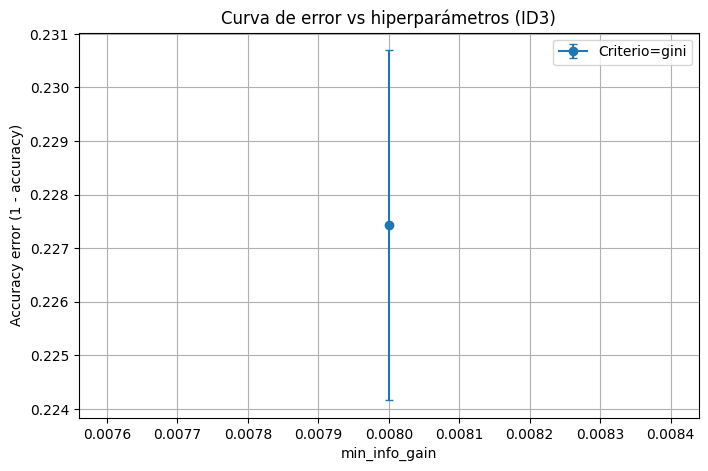

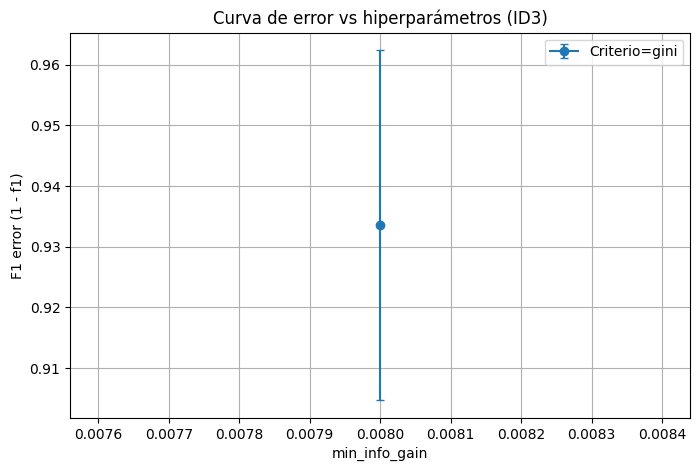


 Resultados CV
criterio  min_info_gain  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
    gini          0.008         0.7726        0.0033   0.0664  0.0288       0.0373      0.0184           0.369         0.0528


In [28]:
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Carga dataset
S = t.cargarDataset("data_dia1")

# Configuración atributos y objetivo válidos
X = S[X_config]

y = S[y_config].squeeze() #pasa de df a serie

# #configuración de hiperparámetros a evaluar
# criterios = ["gain", "gini", "gain_ratio"]
# min_info_gains = [0.003, 0.004, 0.006, 0.008]

criterios = ["gini"]
min_info_gains = [0.008]

# Train/Test split (80/20 estratificado)
X_train, X_test, y_train, y_test, = t.split_data(X,y)

# Validación cruzada para selección de hiperparámetros
df_validacion, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, criterios=criterios, hiperparams=min_info_gains)

t.funcGraficaError(df_validacion, metric="accuracy", modelo="ID3")
t.funcGraficaError(df_validacion, metric="f1", modelo="ID3")

print("\n Resultados CV")
print(df_validacion.round(4).to_string(index=False))

# print("\nMEJOR CONFIGURACIÓN EN TRAIN (según F1):")
# print(best_cfg_F)

# print("\nMEJOR CONFIGURACIÓN EN TRAIN (según accuracy):")
# print(best_cfg_A)

#tiempo est: 16min

#config optima acc: gini, 0.008 (0.7734 mean)

#config optima f1: gini, 0.000. Pero no usaría hiperparámetro nulo. (0.2737 mean)


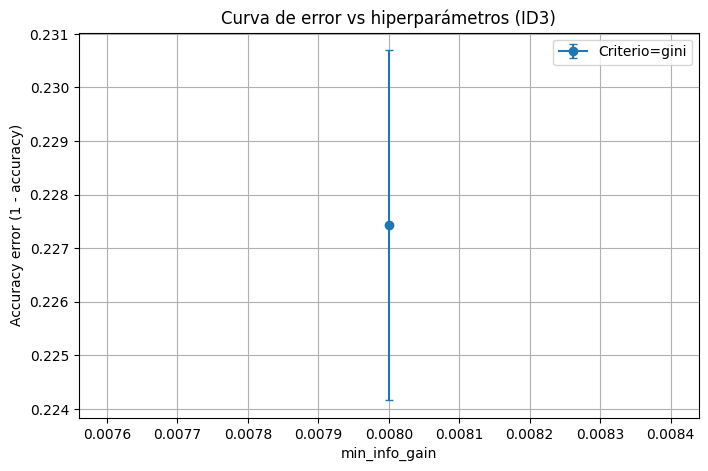

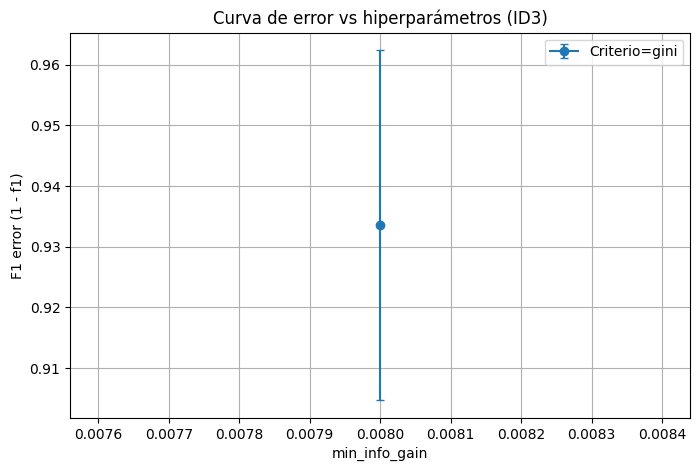

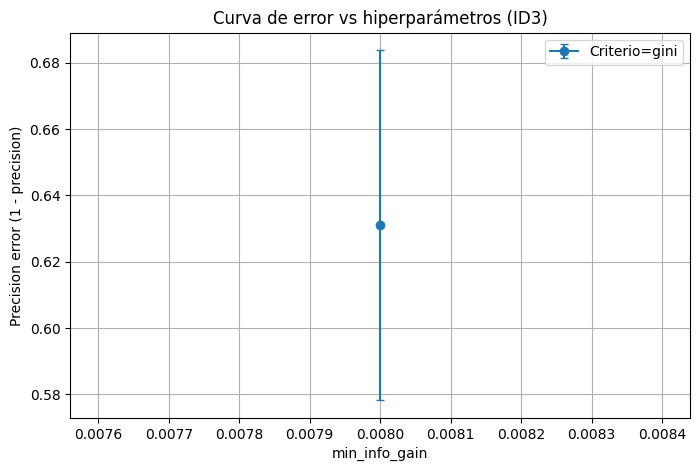

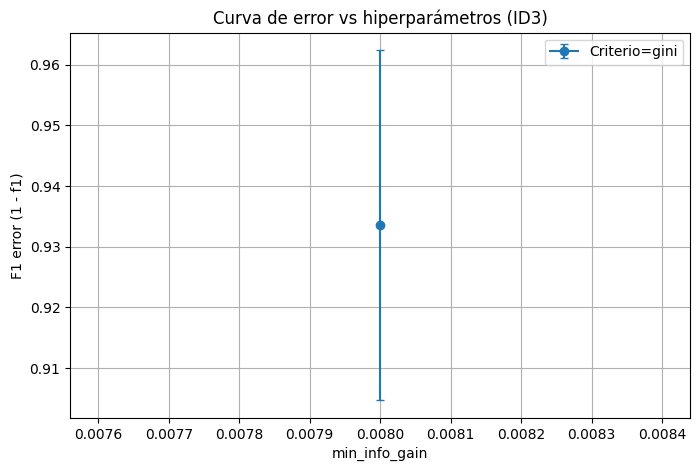

In [30]:
# Gráfica errores segun validacion: 

t.funcGraficaError(df_validacion, metric="accuracy", modelo="ID3")
t.funcGraficaError(df_validacion, metric="f1", modelo="ID3")
t.funcGraficaError(df_validacion, metric="precision", modelo="ID3")
t.funcGraficaError(df_validacion, metric="f1", modelo="ID3")


EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
mejor criterio:  gain mejor min_info_gain:  0.003
Accuracy : 0.7251231527093596
F1       : 0.19827586206896552
Recall   : 0.2799188640973631
Precision: 0.15350389321468297

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
mejor criterio:  gini mejor min_info_gain:  0.008
Accuracy : 0.7724137931034483
F1       : 0.0395010395010395
Recall   : 0.021134593993325918
Precision: 0.30158730158730157

MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score


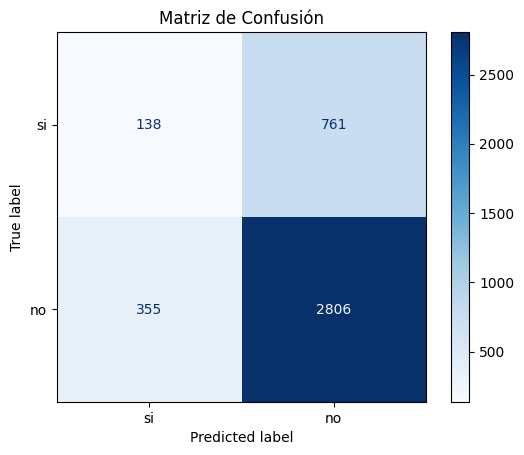


MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy


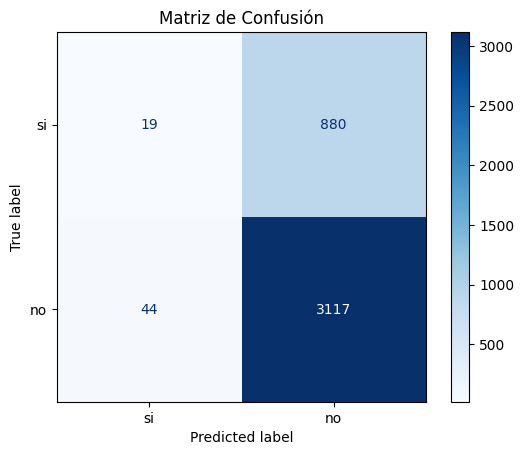

dot: graph is too large for cairo-renderer bitmaps. Scaling by 0.0445457 to fit


'ARBOL min_info gain 0.003 y selección por ganancia.png'

In [22]:
# Evaluación final en test según mejores configuraciones ID3 modificado
y_pred_f = t.testearModelo("ID3", best_cfg_F, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
t.imprimirMetricas("ID3", best_cfg_F,y_pred_f, y_test)

y_pred_a = t.testearModelo("ID3", best_cfg_A, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
t.imprimirMetricas("ID3", best_cfg_A, y_test,y_pred_a)

# Matrices de confusión
print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score")
t.graficar_matriz_confusion(y_test, y_pred_f, labels=['si', 'no'])

print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy")
t.graficar_matriz_confusion(y_test, y_pred_a, labels=['si', 'no'])

arbol = t.generacion_ID3(S, list(X.columns), "dia_lluvioso", 0.003, "gain")
dot = t.graficar_arbol(arbol)
dot.render("ARBOL min_info gain 0.003 y selección por ganancia", format="png", view=True)

#timepo est: 1min

--- Evaluando: nro arboles=100 ---
--- Evaluando: nro arboles=200 ---
--- Evaluando: nro arboles=300 ---
--- Evaluando: nro arboles=500 ---


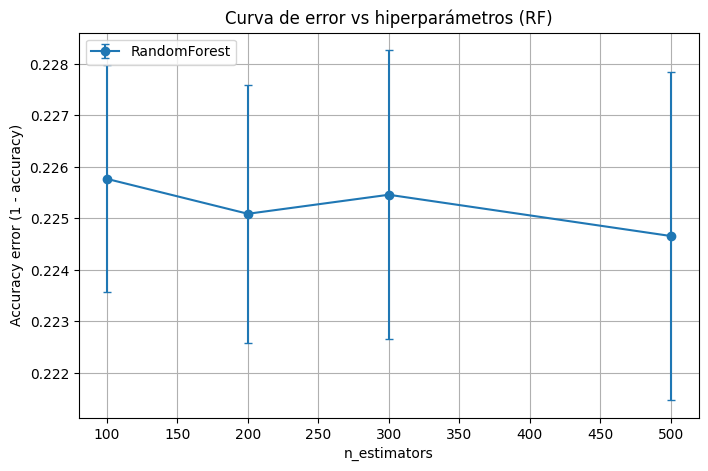

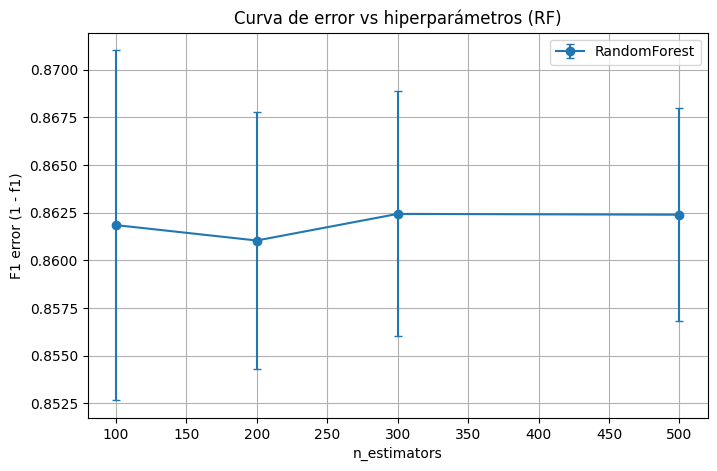


 Resultados CV
 n_estimators  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
          100         0.7742        0.0022   0.1382  0.0092       0.0817      0.0061          0.4484         0.0248
          200         0.7749        0.0025   0.1390  0.0067       0.0820      0.0044          0.4568         0.0294
          300         0.7745        0.0028   0.1376  0.0064       0.0812      0.0040          0.4524         0.0326
          500         0.7753        0.0032   0.1376  0.0056       0.0809      0.0031          0.4621         0.0379


In [33]:
# -------------------------------------------- RANDOM FOREST -------------------------------------------------
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Cargar dataset
S2 = t.cargarDataset("data_dia_c")

# Definir los atributos y objetivo validos
# Configuración atributos y objetivo válidos
X_config.remove("fase_lunar") #eliminamos la fase lunar
X = S2[X_config]

y = S2[y_config].squeeze() #pasa de df a serie

#configuración de hiperparámetros a evaluar
n_estimators_values = [100, 200, 300, 500]

# Train/Test split (80/20 estratificado)
X_train, X_test, y_train, y_test, = t.split_data(X,y)

# Validación cruzada para selección de hiperparámetros
df_validacion, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, hiperparams=n_estimators_values)

print("\n Resultados CV")
print(df_validacion.round(4).to_string(index=False))

# print("\nMEJOR CONFIGURACIÓN EN TRAIN (según F1):")
# print(best_cfg_F)

# print("\nMEJOR CONFIGURACIÓN EN TRAIN (según accuracy):")
# print(best_cfg_A)


#tiempo est: 5 min

#muy semejantes todos, desde los 100 a 2000, no vale la pena agregar mas de 1000 arboles
#config optima acc: 1000 

#config optima f1: 1000

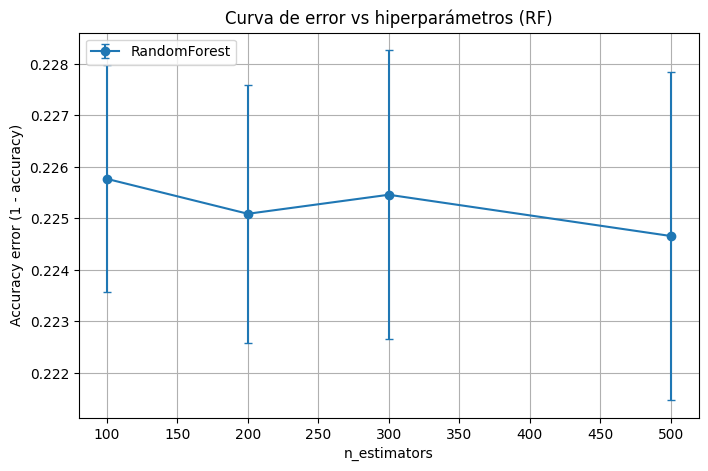

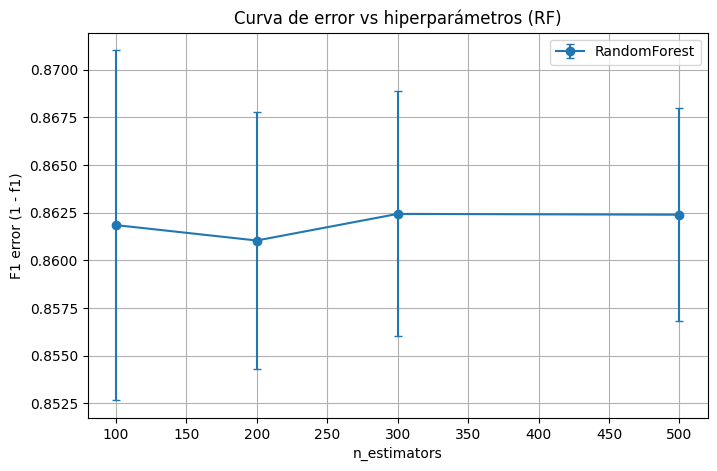

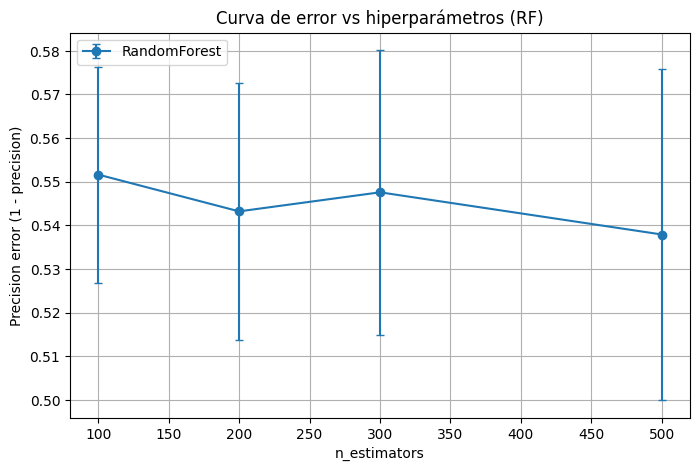

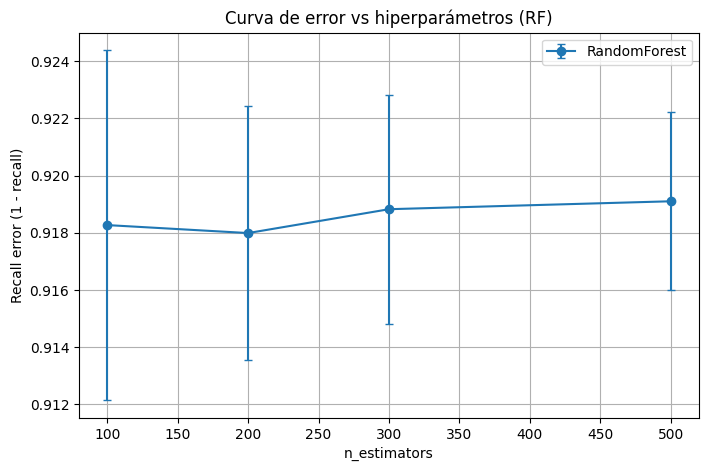

In [34]:
t.funcGraficaError(df_validacion, metric="accuracy", modelo="RF")
t.funcGraficaError(df_validacion, metric="f1", modelo="RF")
t.funcGraficaError(df_validacion, metric="precision", modelo="RF")
t.funcGraficaError(df_validacion, metric="recall", modelo="RF")


EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
nro arboles:  200
Accuracy : 0.7716748768472906
F1       : 0.13283442469597756
Recall   : 0.4176470588235294
Precision: 0.07897664071190211

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
nro arboles:  500
Accuracy : 0.7719211822660098
F1       : 0.12476370510396975
Recall   : 0.07341490545050056
Precision: 0.41509433962264153

MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score


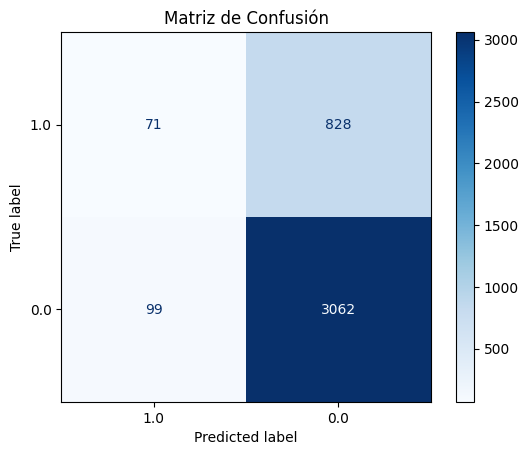


MATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy


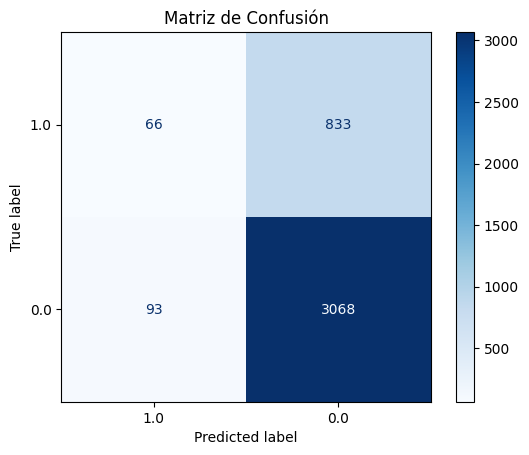

In [24]:
# Evaluación final en test según mejores configuraciones RANDOM FOREST sickit learn
importlib.reload(t)

y_pred_f = t.testearModelo("RF", best_cfg_F, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
t.imprimirMetricas("RF", best_cfg_F, y_pred_f, y_test)

y_pred_a = t.testearModelo("RF", best_cfg_A, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
t.imprimirMetricas("RF", best_cfg_A, y_test, y_pred_a)

# Matrices de confusión
# Matrices de confusión
print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por f-score")
t.graficar_matriz_confusion(y_test, y_pred_f, labels=[1.0, 0.0])

print("\nMATRIZ DE CONFUSIÓN (TEST) según mejor criterio por accuracy")
t.graficar_matriz_confusion(y_test, y_pred_a, labels=[1.0, 0.0])


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import algoritmos_clasificacion as t
import pandas as pd
from sklearn.model_selection import KFold

def crear_lags_concat(X, y, nd):
    """
    Genera variables lag (días previos) hasta 'nd' para cada columna de X.
    Devuelve X_lag e y_lag con las filas sincronizadas y sin NaN.
    """
    lags = {}
    for col in X.columns:
        for d in range(1, nd+1):
            lags[f"{col}_lag{d}"] = X[col].shift(d)

    X_lag = pd.concat([X, pd.DataFrame(lags)], axis=1)

    # Eliminar filas con NaN generadas por shift
    mask = ~X_lag.isna().any(axis=1)
    return X_lag[mask], y[mask]


# Hiperparámetros a probar con Bayes
m_values = [0.5, 1, 2, 5]
nd_values = [3] # [1, 2, 3]

resultados_bayes = {}

S = t.cargarDataset("data_dia1")

X = S[["hum_carrasco","hum_salto","tmax_carrasco","tmin_carrasco","tmax_salto","tmin_salto",
       "amplitud_carrasco","amplitud_salto",
       "dir_viento_carrasco_prom","int_viento_carrasco_prom","int_racha_viento_carrasco_prom",
       "dir_viento_salto_prom","int_viento_salto_prom","int_racha_viento_salto_prom",
       "vis_carrasco_prom","vis_salto_prom"]]

y = S["dia_lluvioso"]

kf = KFold(n_splits=5, shuffle=True, random_state=42)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

for m in m_values:
    for nd in nd_values:
        print(f"\n=== Evaluando Naive Bayes con m={m}, nd={nd} ===")
        
        X_train_lag, y_train_lag = crear_lags_concat(X_train, y_train, nd)
        X_test_lag, y_test_lag = crear_lags_concat(X_test, y_test, nd)

        # Crear modelo
        model = t.NaiveBayesClassifier(m=m, nd=nd)
        
        # Validación cruzada en train
        cv_scores = cross_val_score(model, X_train_lag, y_train_lag, cv=kf)
        resultados_bayes[(m, nd)] = cv_scores
        
        print("Scores por fold:", [round(s,4) for s in cv_scores])
        print(f"Accuracy promedio CV: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
        
        # Entrenar en todo el train y evaluar en test
        model.fit(X_train_lag, y_train_lag)
        y_pred = model.predict(X_test_lag)

        # Accuracy
        acc_test = accuracy_score(y_test_lag, y_pred)
        # F1-score
        f1_test = f1_score(y_test_lag, y_pred, average='binary', pos_label='si')
        # Recall
        recall_test = recall_score(y_test_lag, y_pred, average='binary', pos_label='si')
        # Matriz de confusión
        cm = confusion_matrix(y_test_lag, y_pred, labels=['si','no'])
        
        print(f"Accuracy en test: {acc_test:.4f}")
        print(f"F1-score en test: {f1_test:.4f}")
        print(f"Recall en test: {recall_test:.4f}")
        print("Matriz de confusión:")
        print(cm)
# Resumen final de Naive Bayes para los distintos m y nd
print("\nRESUMEN NAIVE BAYES (Accuracy promedio CV ± desviación)")
for (m, nd), scores in resultados_bayes.items():
    print(f"m={m}, nd={nd} : {scores.mean():.4f} ± {scores.std():.4f}")

ValueError: Dataset 'data_dia' no encontrado.